# 09 · Plausibility vs fidelity
Tema 7: an explanation can be **faithful** (reflects what the model does) and **plausible** (makes sense to a human) independently. Notebook 05 measured fidelity (deletion, label randomisation, stability). Here we measure **plausibility**: do the model's learnt effects agree with established medical knowledge?

**Reference for the expected direction** (only features covered by the sources are scored; everything else is "no reference"):
- CDC Prediabetes Risk Test scoring: age (older = higher), BMI (higher = higher), high blood pressure (yes = higher), physical activity (inactive = higher), sex (man = higher). https://www.cdc.gov/diabetes/widgets/risktest/how-your-test-is-scored.html
- CDC (Diabetes and Prediabetes fact sheet): current smokers have a 30–40 % higher risk of type 2 diabetes. https://www.cdc.gov/chronicdisease/resources/publications/factsheets/diabetes-prediabetes.htm

These are population risk factors for *type 2 diabetes*; the dataset's label is *diagnosed diabetes or prediabetes (self-reported)*, so they are a reasonable but imperfect yardstick.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, shap, warnings
from functools import partialmethod
from tqdm import tqdm; tqdm.__init__ = partialmethod(tqdm.__init__, disable=True)
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
from src.preprocess import get_splits
from src.evaluation import threshold_for_recall
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
X_tr, X_va, X_te, y_tr, y_va, y_te = get_splits()
full = joblib.load("../models/lightgbm.joblib"); red = joblib.load("../models/lightgbm_reduced.joblib")
keep = [c for c in X_tr.columns if c not in ["CholCheck", "HvyAlcoholConsump", "AnyHealthcare"]]
idx = np.random.default_rng(0).choice(len(X_te), 5000, replace=False); Xs = X_te.iloc[idx]; bg = X_tr.sample(100, random_state=0)
sv_f = pd.DataFrame(shap.TreeExplainer(full, data=bg, feature_perturbation="interventional", model_output="raw")(Xs).values, columns=X_tr.columns, index=Xs.index)
sv_r = pd.DataFrame(shap.TreeExplainer(red, data=bg[keep], feature_perturbation="interventional", model_output="raw")(Xs[keep]).values, columns=keep, index=Xs.index)
# direction learnt by the model = sign of the rank correlation between feature value and its SHAP value
direction = lambda S, f: spearmanr(Xs[f], S[f])[0]

 19%|====                | 928/5000 [00:11<00:48]       

 20%|====                | 1019/5000 [00:12<00:46]       

 22%|====                | 1111/5000 [00:13<00:45]       

 24%|=====               | 1202/5000 [00:14<00:44]       

 26%|=====               | 1292/5000 [00:15<00:43]       

...

 89%|==================  | 4458/5000 [00:40<00:04]       

 92%|==================  | 4577/5000 [00:41<00:03]       

 94%|=================== | 4690/5000 [00:42<00:02]       

 96%|=================== | 4802/5000 [00:43<00:01]       

 98%|===================| 4917/5000 [00:44<00:00]       

## 1. Direction of the learnt effects vs the CDC expectation

In [3]:
expected = {"Age": (+1, "older = higher risk (CDC risk test)"), "BMI": (+1, "higher BMI = higher risk (CDC risk test)"),
            "HighBP": (+1, "high blood pressure = higher risk (CDC risk test)"), "PhysActivity": (-1, "active = lower risk (CDC risk test)"),
            "Sex": (+1, "man = higher risk (CDC risk test; Sex=1 is male)"), "Smoker": (+1, "smoking raises risk 30-40 % (CDC fact sheet)")}
rows = []
for f, (sgn, why) in expected.items():
    d = direction(sv_r, f)
    rows.append({"feature": f, "expected": "+" if sgn > 0 else "−", "learnt (corr value~SHAP)": round(d, 2), "agrees": np.sign(d) == sgn, "mean |SHAP|": round(sv_r[f].abs().mean(), 3),
                 "importance rank (of 18)": int(sv_r.abs().mean().rank(ascending=False)[f]), "source": why})
pl = pd.DataFrame(rows); print(f"direction agreement: {pl.agrees.sum()} of {len(pl)} features with a source"); pl

direction agreement: 5 of 6 features with a source


,feature,expected,learnt (corr value~SHAP),agrees,mean |SHAP|,importance rank (of 18),source
0,Age,+,0.92,True,0.409,2,older = higher risk (CDC risk test)
1,BMI,+,0.99,True,0.387,3,higher BMI = higher risk (CDC risk test)
2,HighBP,+,0.86,True,0.352,4,high blood pressure = higher risk (CDC risk test)
3,PhysActivity,−,-0.32,True,0.006,17,active = lower risk (CDC risk test)
4,Sex,+,0.86,True,0.116,6,man = higher risk (CDC risk test; Sex=1 is male)
5,Smoker,+,-0.86,False,0.030,11,smoking raises risk 30-40 % (CDC fact sheet)


## 2. Features the model relies on that have **no** medical rationale in these sources
Learnt direction of the features that the CDC sources do not cover, in the **full** model (21 features). The three artefact features are the interesting ones.

In [4]:
others = [f for f in X_tr.columns if f not in expected]
tab = pd.DataFrame({"mean |SHAP| (full)": sv_f[others].abs().mean(), "learnt direction (corr value~SHAP)": [direction(sv_f, f) for f in others]}, index=others).round(3).sort_values("mean |SHAP| (full)", ascending=False)
tab["artefact feature (notebook 03)"] = tab.index.isin(["CholCheck", "HvyAlcoholConsump", "AnyHealthcare"])
tab

,mean |SHAP| (full),learnt direction (corr value~SHAP),artefact feature (notebook 03)
GenHlth,0.503,0.958,False
HighChol,0.274,0.860,False
CholCheck,0.119,0.363,True
Income,0.109,-0.955,False
MentHlth,0.093,-0.794,False
HeartDiseaseorAttack,0.084,0.514,False
HvyAlcoholConsump,0.066,-0.438,True
DiffWalk,0.062,0.665,False
PhysHlth,0.024,-0.140,False
Stroke,0.023,0.358,False


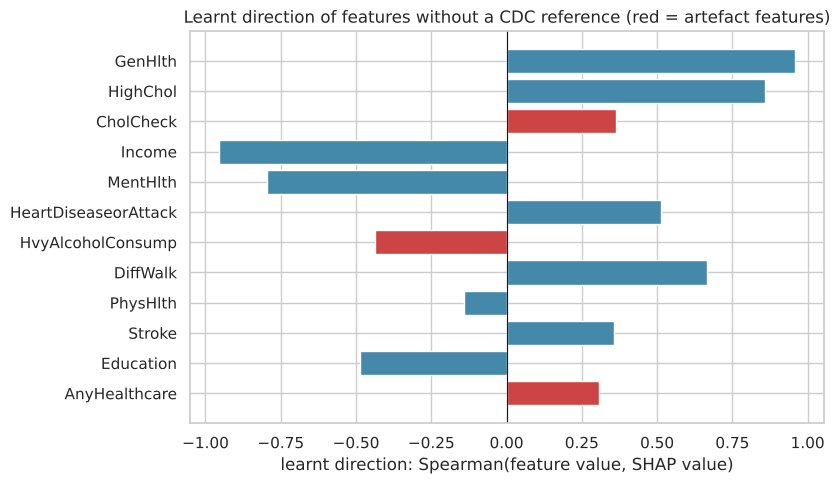

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 5)); t = tab.head(12)[::-1]
ax.barh(t.index, t["learnt direction (corr value~SHAP)"], color=["#c44" if a else "#48a" for a in t["artefact feature (notebook 03)"]])
ax.axvline(0, c="k", lw=.8); ax.set_xlabel("learnt direction: Spearman(feature value, SHAP value)"); ax.set_title("Learnt direction of features without a CDC reference (red = artefact features)")
plt.tight_layout(); plt.savefig("../figures/plausibility_directions.png", dpi=150); plt.show()

## 3. Fidelity × plausibility (Tema 7 table)
Direction agreement with the CDC sources: **5 of 6** features (Age, BMI, blood pressure, sex and physical activity agree; **smoking does not**: the model learns a slightly *protective* effect, opposite to the CDC's +30–40 %; its importance is small, rank 11 of 18, and it is probably confounded with age/health status).

| | **Plausible** (agrees with medical knowledge) | **Not plausible** |
|---|---|---|
| **Faithful** (sanity checks pass) | Age, BMI, blood pressure, sex, physical activity: the explanation can be trusted and makes sense | `CholCheck`, `HvyAlcoholConsump`, `AnyHealthcare` (detection-bias shortcuts); `Smoker` (reversed direction, small effect); `MentHlth` (more bad-mental-health days → *lower* risk once general health is accounted for; likely a collinearity effect with `GenHlth`/`PhysHlth`, a hypothesis not checked here) |
| **Unfaithful** | not observed here (SHAP passes deletion, label-randomisation and stability checks) | — |

The valuable cell is *faithful but not plausible*: a human who only checks "does it look reasonable" would reject these explanations, yet they reveal what the model learnt about the data-collection process and about correlated features. Note that fidelity here is to the **model**, not to the real world: a faithful explanation of a model that learnt a confounded effect is still misleading if read causally.